# 4. Recovering the Unsupervised Taxonomy: Affinity Propagation, Modal Plateau & Scaling Laws

**What you will learn:**
1. How **Affinity Propagation (AP)** converts a fused similarity matrix $S^\star$ into the number of behaviors $C$, their partition, and **real exemplar runs** without assuming $C$ upfront (`preference = median(S*)`, `damping = 0.9`, original convergence window `100`).
2. How sweeping the local $9 \times 11 = 99$ resolution grid reveals the **modal plateau** ($C^\star = 5$ on `84/99` settings for Top-1, `0` misassigned runs).
3. What happens when controllers are pooled (`Top-1` $\to$ `Top-10`, `250` $\to$ `2,500` runs): why **homogeneity stays $\ge 0.997$** and **purity $= 0.999\text{--}1.000$** while completeness decreases only because genuine behavioral sub-strategies appear inside missions.
4. How transitions across the wide proportional window ($k_{\mathrm{nn}} \le 50n$) obey the power law $k_{\mathrm{nn}}/n = 131\,t^{-0.55}$ and isolate atypical controllers (`10th` Shelter, `10th` XOR) without labels.

In [1]:
import pickle, sys
from pathlib import Path
from IPython.display import Image, display
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "src"), str(ROOT)]

import figlib as L
import make_figures as M
import run_sweep as RS
from classification import fusion as F
L.style()

PAPER = ROOT / "results" / "epuck" / "paper"
load = lambda p: pickle.load(open(p, "rb"))

## 1. Running Affinity Propagation & Inspecting the Top-1 Resolution Grid

At a single resolution $(k_{\mathrm{nn}}=7, t=10)$, AP passes responsibility and availability messages until every recording points to an actual **exemplar recording**. Sweeping $(k_{\mathrm{nn}}, t)$ over $9 \times 11 = 99$ local settings verifies stability without labels.

Single run (knn=7, t=10): C = 5, exemplars = [24, 79, 105, 170, 244], converged = True
Scores vs missions: {'C': 5, 'purity': 1.0, 'ari': 1.0, 'nmi': 1.0}


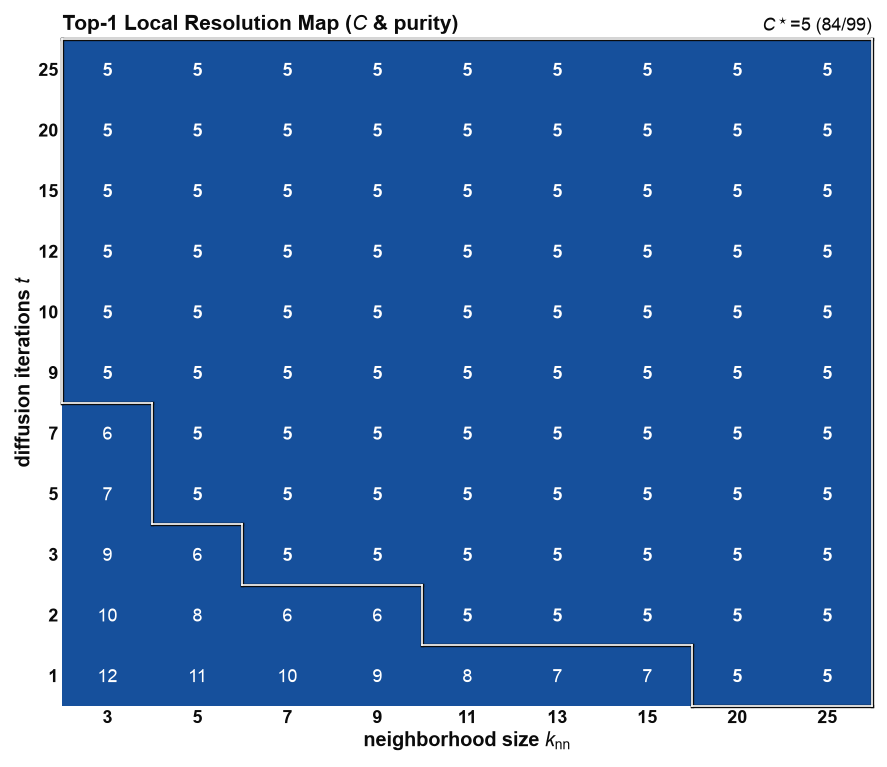

In [2]:
lab, rk, ctrl = RS.load_labels()
D, _ = RS.load_distances()
idx = RS.subset(1, rk); y = lab[idx]

out = F.run(F.rank_normalise(D, F.ALL_FIELDS, idx), knn=7, t=10)
print(f"Single run (knn=7, t=10): C = {len(np.unique(out['labels']))}, exemplars = {out['exemplars'].tolist()}, converged = {out['converged']}")
print("Scores vs missions:", RS.score(y, out["labels"]))

G = load(PAPER / "grid.pkl")
fig, ax = plt.subplots(figsize=(6.0, 5.2))
M.resolution_panel(ax, G[1]["results"], "Top-1 Local Resolution Map ($C$ & purity)")
plt.tight_layout(); plt.show()

## 2. Modal Consensus, Co-Association Matrix & Exemplar Selection Frequency

Rather than cherry-picking one $(k_{\mathrm{nn}}, t)$ point, the **modal consensus** aggregates all settings where $C = C^\star$ (`84/99` on Top-1) into a co-association matrix and cuts it by average linkage. Each cluster picks the member chosen most frequently by AP across the plateau.

Modal plateau: C* = 5 on 84/99 settings, stability = 1.000
Modal consensus scores: {'C': 5, 'purity': 1.0, 'ari': 1.0, 'nmi': 1.0}


/tmp/ipykernel_362282/1889302572.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


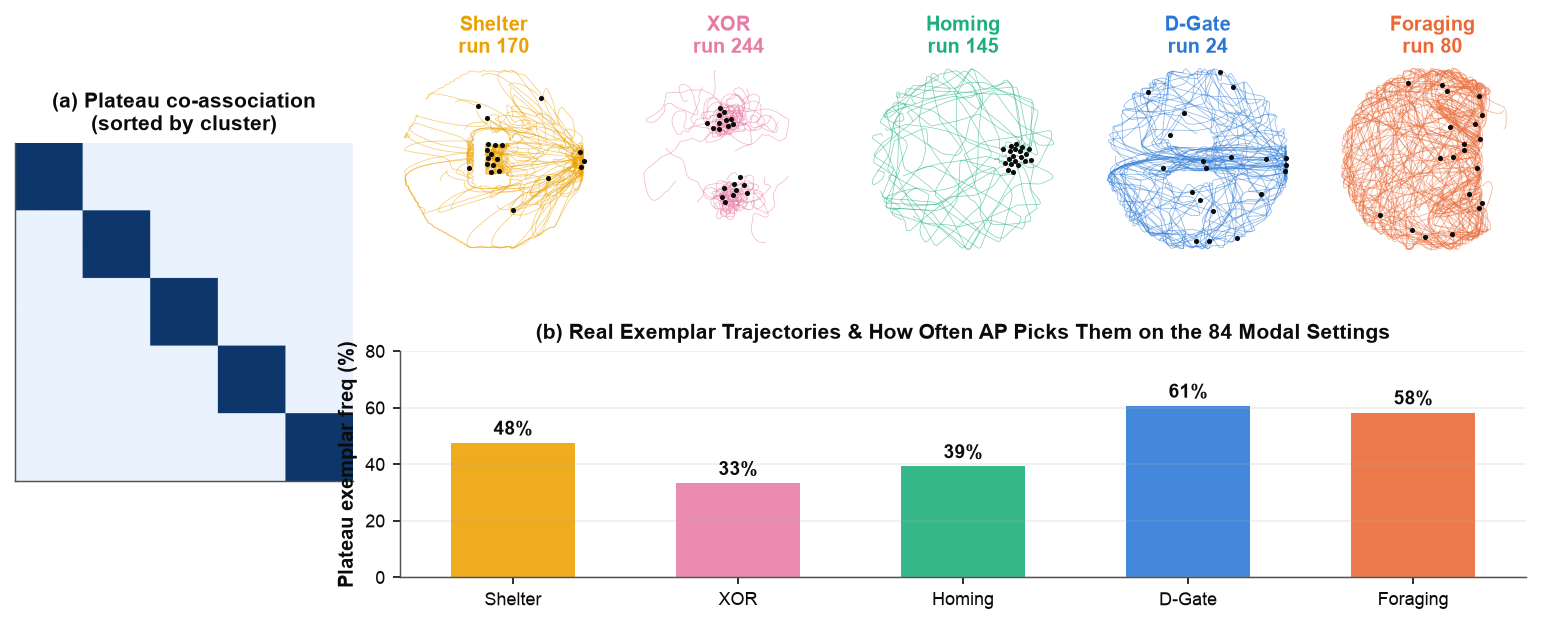

In [3]:
pc = F.plateau_consensus(G[1]["results"], len(y))
print(f"Modal plateau: C* = {pc['C']} on {pc['n_plateau']}/99 settings, stability = {pc['stability']:.3f}")
print("Modal consensus scores:", RS.score(y, pc["labels"]))

d = load(PAPER / "top1_tracks.pkl")
order = np.argsort(pc["labels"], kind="stable")

fig = plt.figure(figsize=(13.0, 4.6))
gs = fig.add_gridspec(2, 6, width_ratios=[1.8, 1, 1, 1, 1, 1], wspace=0.22, hspace=0.35)
ax_co = fig.add_subplot(gs[:, 0])
ax_co.imshow(pc["coassociation"][np.ix_(order, order)], cmap=L.SEQ, vmin=0, vmax=1)
ax_co.set_title("(a) Plateau co-association\n(sorted by cluster)", fontsize=10, fontweight="bold")
ax_co.set_xticks([]); ax_co.set_yticks([])

freqs = []
mnames = []
cols = []
for k, e in enumerate(pc["exemplars"]):
    m = int(y[e])
    ax_t = fig.add_subplot(gs[0, k + 1])
    M.draw_tracks(ax_t, d["tracks"][e]["pos"], L.MCOL[m], every=6)
    ax_t.set_title(f"{L.MSHORT[m]}\nrun {e}", color=L.MCOL[m], fontsize=9.5, fontweight="bold")
    freqs.append(100 * pc["exemplar_frequency"][k])
    mnames.append(L.MSHORT[m])
    cols.append(L.MCOL[m])

ax_bar = fig.add_subplot(gs[1, 1:])
bars = ax_bar.bar(mnames, freqs, color=cols, alpha=0.88, width=0.55)
for b, fr in zip(bars, freqs):
    ax_bar.text(b.get_x() + b.get_width()/2, fr + 1.5, f"{fr:.0f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax_bar.set_ylim(0, 80); ax_bar.set_ylabel("Plateau exemplar freq (%)")
ax_bar.set_title("(b) Real Exemplar Trajectories & How Often AP Picks Them on the 84 Modal Settings", fontsize=10, fontweight="bold")
ax_bar.grid(axis="y", alpha=0.2)
plt.tight_layout(); plt.show()

## 3. Scaling From `Top-1` (250 Runs) to `Top-10` (2,500 Runs)

When up to 10 AutoMoDe controllers per mission are pooled, **homogeneity** remains near `1.000` (`>= 0.997`) and **purity** stays `0.999–1.000` (`6` misassigned runs across all `13,750` runs!). Meanwhile **completeness** and **ARI** drop purely because clusters uncover multiple distinct behavioral strategies *within* missions (`figA_pooled`). Notice how $C^\star$ saturates at `11` on `Top-8..10` — 50 controllers realize only ~11 distinct kinematic behaviors!

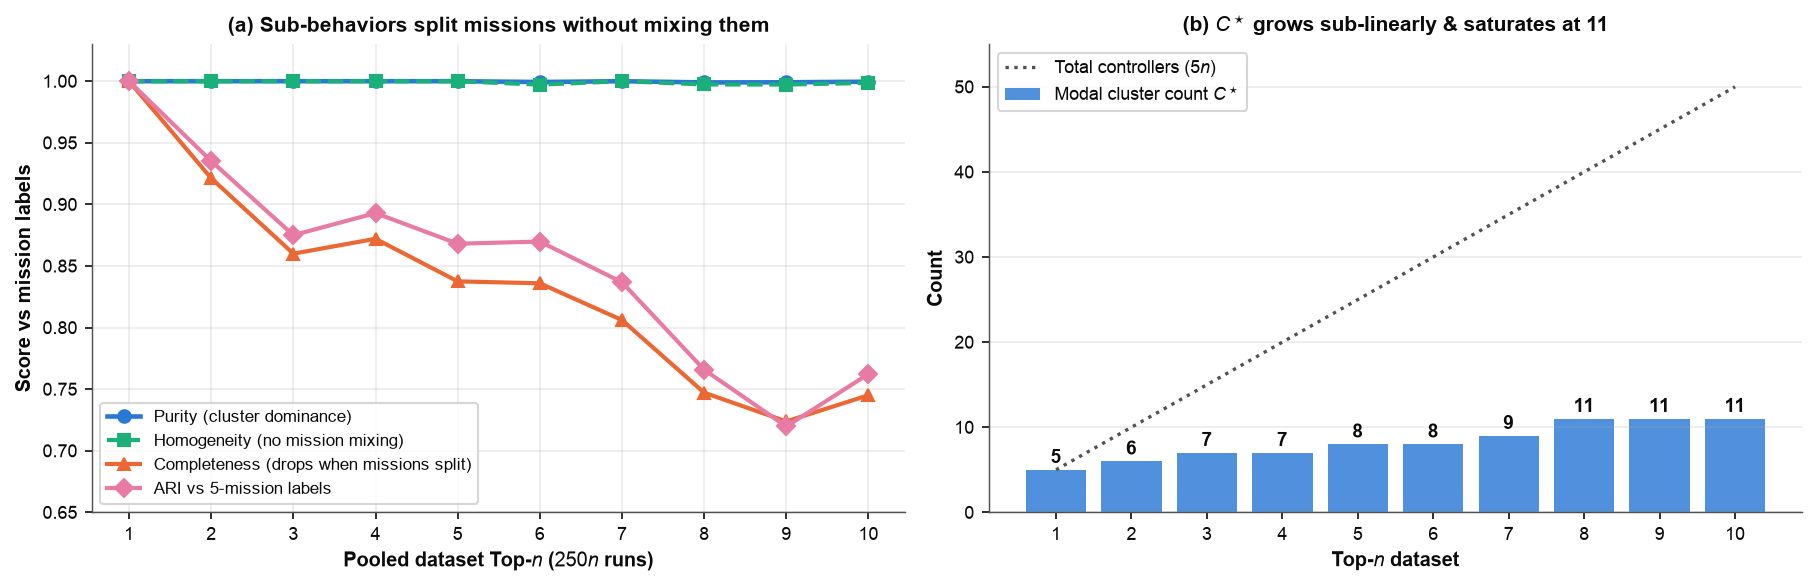

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_resolution_map.pdf
WARNING fig_resolution_map: 60 texts below 8.5 pt on the page (scale 0.902): '$C^\\star\\!=\\!11$ (17/99)' 7.7 pt, '$C^\\star\\!=\\!11$ (18/99)' 7.7 pt, '$C^\\star\\!=\\!11$ (19/99)' 7.7 pt, '$C^\\star\\!=\\!5$ (84/99)' 7.7 pt, '$C^\\star\\!=\\!6$ (33/99)' 7.7 pt, '$C^\\star\\!=\\!7$ (32/99)' 7.7 pt ...
        content outside the canvas, inches: left 0.000, right 0.000


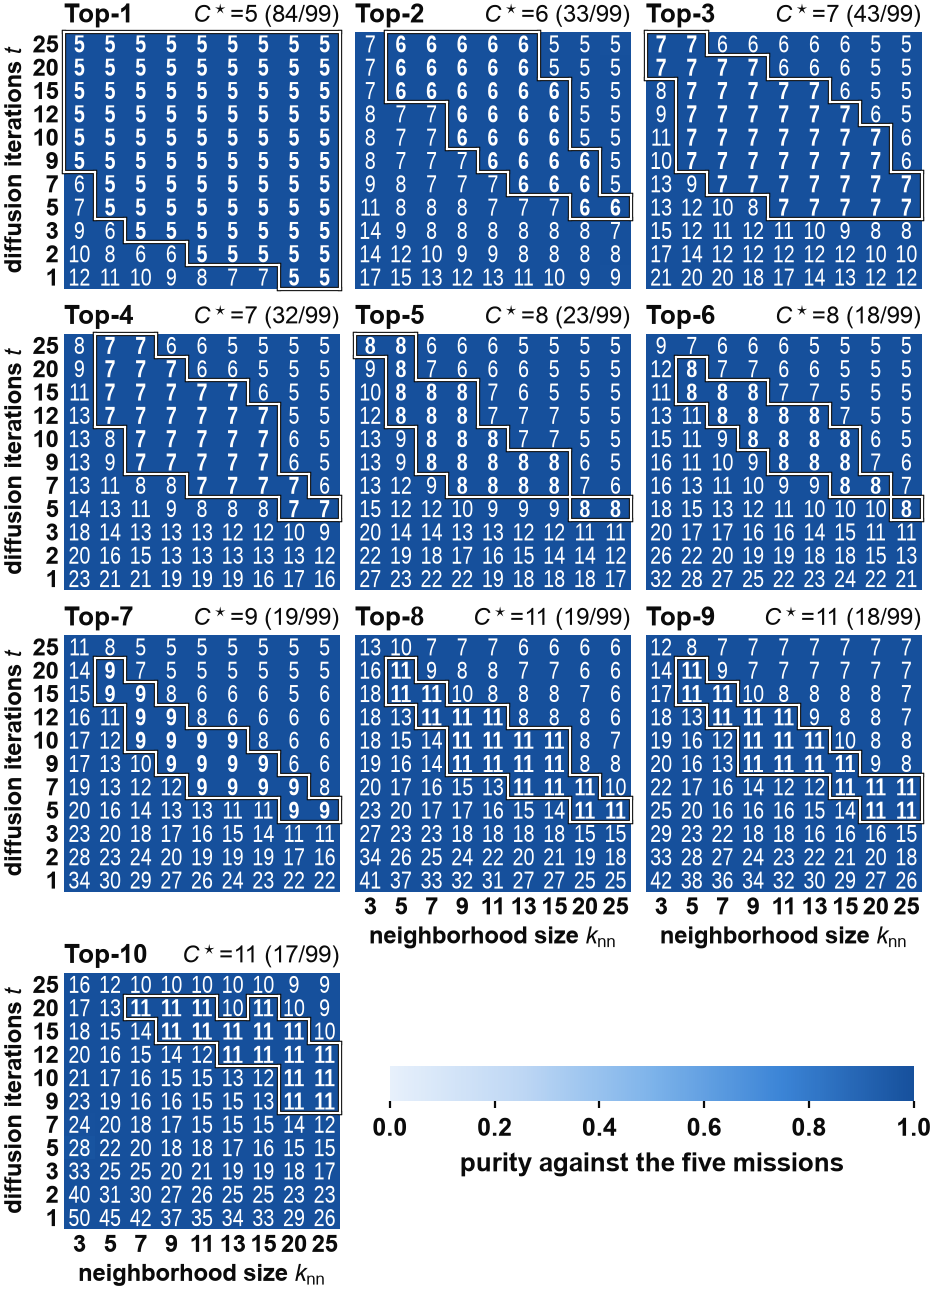

saved /home/ndinga/Documents/paper_topological_kinematics/figures/figA_pooled.pdf


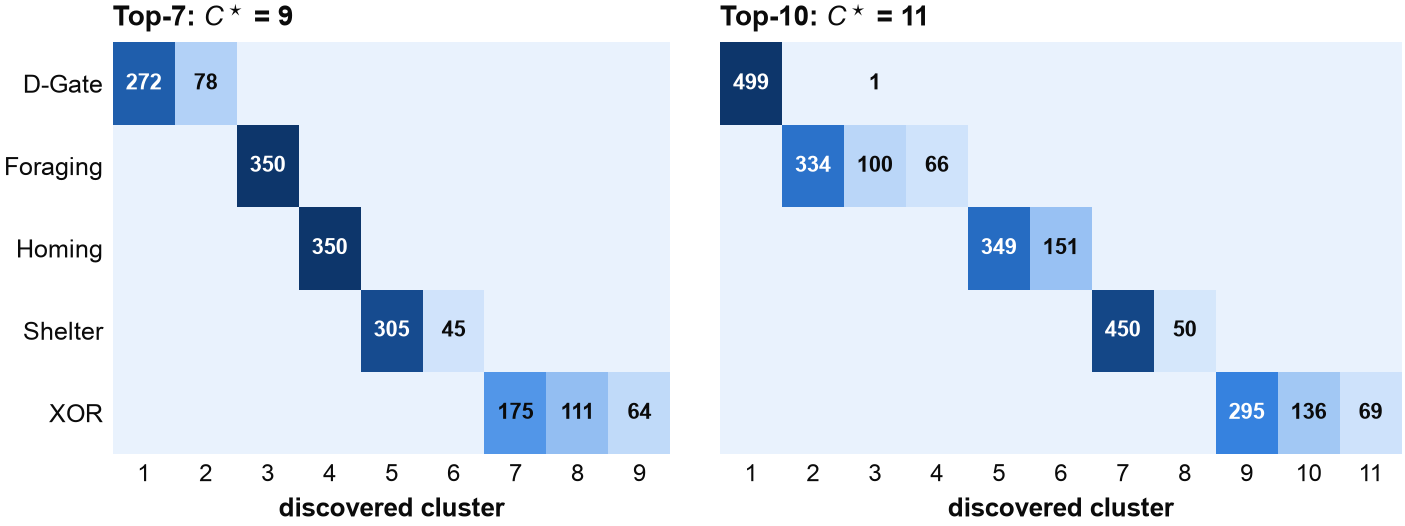

In [4]:
T = load(PAPER / "taxonomy.pkl")
tops = sorted(T.keys())
cstar = [T[k]["C"] for k in tops]
pur = [T[k]["purity"] for k in tops]
hom = [T[k]["homogeneity"] for k in tops]
comp = [T[k]["completeness"] for k in tops]
ari = [T[k]["ari"] for k in tops]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12.2, 4.0))
ax0.plot(tops, pur, marker="o", lw=2.2, color=L.MCOL[0], label="Purity (cluster dominance)")
ax0.plot(tops, hom, marker="s", lw=2.0, ls="--", color=L.MCOL[2], label="Homogeneity (no mission mixing)")
ax0.plot(tops, comp, marker="^", lw=2.0, color=L.MCOL[1], label="Completeness (drops when missions split)")
ax0.plot(tops, ari, marker="D", lw=2.0, color=L.MCOL[4], label="ARI vs 5-mission labels")
ax0.set_xticks(tops); ax0.set_ylim(0.65, 1.03); ax0.set_xlabel("Pooled dataset Top-$n$ ($250n$ runs)")
ax0.set_ylabel("Score vs mission labels"); ax0.set_title("(a) Sub-behaviors split missions without mixing them", fontweight="bold")
ax0.legend(fontsize=8, loc="lower left"); ax0.grid(alpha=0.25)

ax1.bar(tops, cstar, color=L.MCOL[0], alpha=0.82, label=r"Modal cluster count $C^\star$")
ax1.plot(tops, [5*k for k in tops], color=L.INK2, ls=":", lw=1.6, label="Total controllers ($5n$)")
for k, c_val in zip(tops, cstar):
    ax1.text(k, c_val + 0.8, str(c_val), ha="center", fontsize=9, fontweight="bold")
ax1.set_xticks(tops); ax1.set_ylim(0, 55); ax1.set_xlabel("Top-$n$ dataset")
ax1.set_ylabel("Count"); ax1.set_title(r"(b) $C^\star$ grows sub-linearly & saturates at 11", fontweight="bold")
ax1.legend(fontsize=8.5, loc="upper left"); ax1.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

M.fig_resolution(); display(Image(filename=str(ROOT / "figures/fig_resolution_map.png"), width=750))
M.fig_pooled(); display(Image(filename=str(ROOT / "figures/figA_pooled.png"), width=880))

## 4. Global Resolution States & Scaling Law of Transitions ($k_{\mathrm{nn}}/n = 131\,t^{-0.55}$)

Expanding $k_{\mathrm{nn}}$ up to $50n$ reveals nested stable states from sub-behaviors $\to$ 5 missions $\to$ 4/3 motion families. On regular pooled sets (`Top-2..7`), the boundary collapses along a random-walk curve $k_{\mathrm{nn}}/n \propto t^{-0.55}$. Adding the weakest controllers (`Top-8..10`) steepens the exponent and exposes atypical strategies (`10th` Shelter controller moving like Foraging/D-Gate; `10th` XOR settling like Shelter) completely without labels!

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_states.pdf


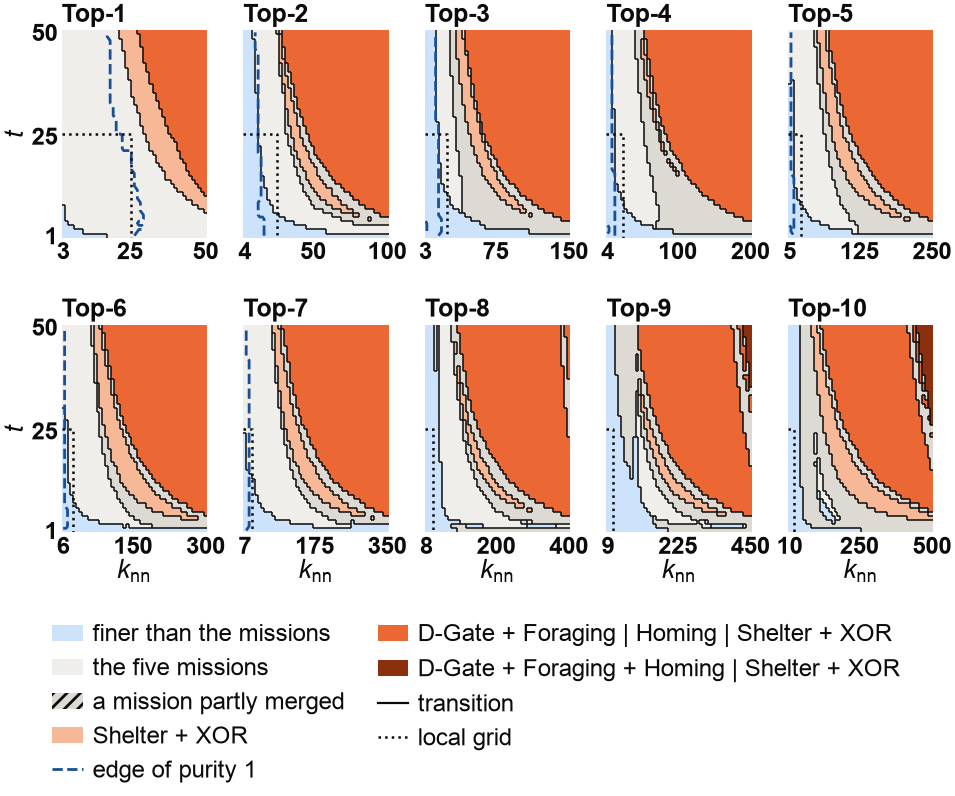

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_law.pdf


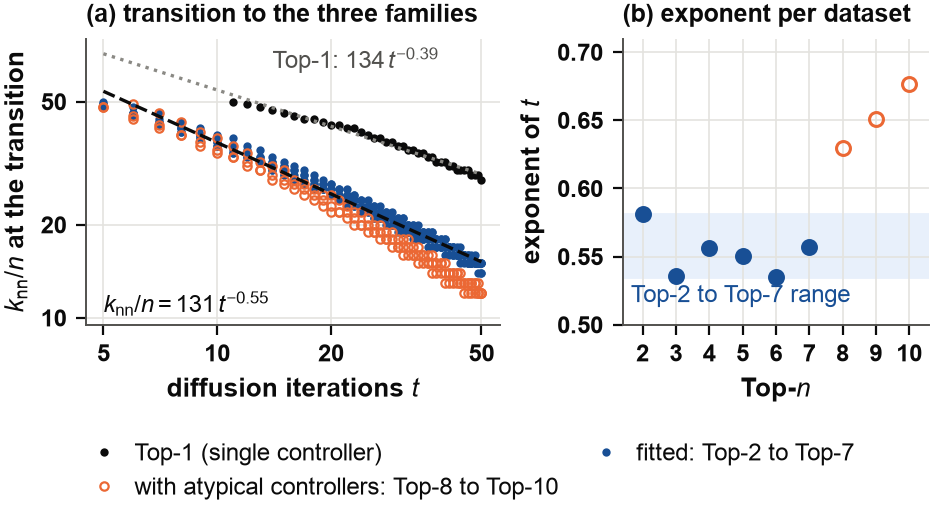

In [5]:
M.fig_states(); display(Image(filename=str(ROOT / "figures/fig_states.png"), width=880))
M.fig_law(); display(Image(filename=str(ROOT / "figures/fig_law.png"), width=850))